# Data Mining – Laboratorium nr 2
## Przygotowanie i wstępna obróbka danych

Zbiór danych: **UCI Online Retail II** (pliki w folderze `Materiały`).

### Wczytywanie zbioru danych

In [1]:
import pandas as pd
import numpy as np

transakcje_09_10 = pd.read_csv('Materiały/online_retail_09_10.csv', sep=',',
                               dtype={'InvoiceNo': str, 'StockCode': str})
transakcje_10_11 = pd.read_csv('Materiały/online_retail_10_11.csv', sep=',',
                               dtype={'InvoiceNo': str, 'StockCode': str})

transakcje = pd.concat(
    [transakcje_09_10, transakcje_10_11], ignore_index=True)

print(transakcje.shape)
transakcje.head()

(1067371, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


### Transakcje dotyczące produktu 84598

In [2]:
produkt_84598 = transakcje[transakcje['StockCode'] == '84598']
print(produkt_84598[['Quantity', 'UnitPrice', 'CustomerID']][:25])

       Quantity  UnitPrice  CustomerID
217         576       0.21     16167.0
2293          1       0.43         NaN
5575         14       0.43         NaN
9861          5       0.43         NaN
19023         1       0.43         NaN
20154         3       0.43         NaN
20409         7       0.43         NaN
30468        28       0.43         NaN
30983         9       0.43         NaN
31565         4       0.43         NaN
31960         2       0.43         NaN
33029       288       0.21     13405.0
40784         9       0.43         NaN
41196         6       0.43         NaN
43884         9       0.43         NaN
50617        11       0.43         NaN
55272         6       0.43         NaN
62563         5       0.43         NaN
65608         5       0.43         NaN
75122        11       0.43         NaN
78034         4       0.43         NaN
79504         8       0.43         NaN
83527        29       0.43         NaN
88500       288       0.21     15807.0
93724       288       0.2

### Średnia cena jednostkowa produktu 84598 a obecność numeru klienta

In [3]:
produkt_84598_zwykła_sprzedaż = produkt_84598.loc[
    (produkt_84598["Quantity"] > 0) & (produkt_84598["UnitPrice"] > 0)].copy()

produkt_84598_zwykła_sprzedaż.loc[:, 'HasCustomerID'] = np.where(
    produkt_84598_zwykła_sprzedaż['CustomerID'].notna(),
    'Yes',
    'No')

print(produkt_84598_zwykła_sprzedaż.groupby('HasCustomerID').agg(
    ŚredniaCenaJednostkowa=("UnitPrice", 'mean')))

               ŚredniaCenaJednostkowa
HasCustomerID                        
No                           0.410111
Yes                          0.206098


### Kolumna opisująca rodzaj transakcji

In [4]:
warunki = [
    transakcje["InvoiceNo"].astype(str).str.startswith("C"),

    (transakcje["Quantity"] > 0) & (transakcje["UnitPrice"] > 0)
    & transakcje["CustomerID"].notna(),

    (transakcje["Quantity"] > 0) & (transakcje["UnitPrice"] > 0)
    & transakcje["CustomerID"].isna(),

    (transakcje["Quantity"] > 0) & (transakcje["UnitPrice"] == 0)
    & transakcje["CustomerID"].notna(),

    (transakcje["Quantity"] > 0) & (transakcje["UnitPrice"] == 0)
    & transakcje["CustomerID"].isna(),

    (transakcje["Quantity"] < 0) & (transakcje["UnitPrice"] == 0)]

kategorie = [
    "anulowanie_bądź_zwrot",
    "standardowa_sprzedaż_klient",
    "sprzedaż_brak_klienta",
    "wydanie_bez_opłaty_klient",
    "wydanie_bez_opłaty_brak_klienta",
    "korekta_stanów_magazynowych"]

transakcje.loc[:, "RodzajTransakcji"] = np.select(
    warunki, kategorie, default="inny")

print(transakcje["RodzajTransakcji"].value_counts())

RodzajTransakcji
standardowa_sprzedaż_klient        805549
sprzedaż_brak_klienta              236121
anulowanie_bądź_zwrot               19494
korekta_stanów_magazynowych          3457
wydanie_bez_opłaty_brak_klienta      2674
wydanie_bez_opłaty_klient              71
inny                                    5
Name: count, dtype: int64


### Ćwiczenie 1 – Czy wydania bez opłaty dla klienta to gratisy/próbki?

Lista unikatowych faktur z transakcjami klasy `wydanie_bez_opłaty_klient`, następnie wszystkie
rekordy z tych faktur, posortowane po `InvoiceNo` i `UnitPrice`.

In [5]:
faktury_bez_opłaty = transakcje.loc[
    transakcje["RodzajTransakcji"] == "wydanie_bez_opłaty_klient", "InvoiceNo"].unique().tolist()
print("Liczba faktur z bezpłatnym wydaniem:", len(faktury_bez_opłaty))

faktury_bez_opłaty_df = (
    transakcje[transakcje["InvoiceNo"].isin(faktury_bez_opłaty)]
    .sort_values(["InvoiceNo", "UnitPrice"]))

pd.set_option('display.max_rows', 60)
faktury_bez_opłaty_df[["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]].head(60)

Liczba faktur z bezpłatnym wydaniem: 61


,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
4674,489825,6 RIBBONS EMPIRE,12,0.00,16126.0
4675,489825,BIRD DECORATION GREEN SPOT,12,0.85,16126.0
4676,489825,BIRD DECORATION RED SPOT,12,0.85,16126.0
4671,489825,PINK CREAM FELT CRAFT TRINKET BOX,24,1.25,16126.0
4672,489825,PINK BLUE FELT CRAFT TRINKET BOX,24,1.25,16126.0
4673,489825,FELTCRAFT BUTTERFLY HEARTS,12,1.45,16126.0
4681,489825,BAKING SET 9 PIECE RETROSPOT,3,4.95,16126.0
4680,489825,CROSS STITCH ALPHABET CUSHION COVER,3,5.95,16126.0
4679,489825,VINTAGE CREAM 3 BASKET CAKE STAND,2,9.95,16126.0
4677,489825,RETRO SPOT CAKE STAND,1,10.95,16126.0


In [6]:
pozycje_na_fakturze = faktury_bez_opłaty_df.groupby("InvoiceNo").agg(
    Liczba_Pozycji=("StockCode", "size"),
    Pozycje_Płatne=("UnitPrice", lambda c: (c > 0).sum()),
    Pozycje_Bezpłatne=("UnitPrice", lambda c: (c == 0).sum()))

z_płatnymi = (pozycje_na_fakturze["Pozycje_Płatne"] > 0)
print("Faktury z pozycjami płatnymi i bezpłatnymi:", z_płatnymi.sum())
print("Faktury zawierające wyłącznie pozycje bezpłatne:", (~z_płatnymi).sum())
print(f"Odsetek faktur mieszanych: {z_płatnymi.mean():.1%}")

print("\nNajczęstsze opisy bezpłatnych pozycji:")
print(transakcje.loc[transakcje["RodzajTransakcji"] == "wydanie_bez_opłaty_klient",
                     "Description"].value_counts().head(15))

Faktury z pozycjami płatnymi i bezpłatnymi: 55
Faktury zawierające wyłącznie pozycje bezpłatne: 6
Odsetek faktur mieszanych: 90.2%

Najczęstsze opisy bezpłatnych pozycji:


Description
Manual                             7
CHRISTMAS PUDDING TRINKET POT      2
This is a test product.            2
REGENCY CAKESTAND 3 TIER           2
ROUND CAKE TIN VINTAGE GREEN       2
6 RIBBONS EMPIRE                   1
DOOR MAT FAIRY CAKE                1
CHRISTMAS CRAFT WHITE FAIRY        1
ANTIQUE LILY FAIRY LIGHTS          1
ANTIQUE GLASS HEART DECORATION     1
 FLAMINGO LIGHTS                   1
CHARLOTTE BAG , SUKI DESIGN        1
RETRO SPOT LARGE MILK JUG          1
VINTAGE GLASS COFFEE CADDY         1
CAST IRON HOOK GARDEN TROWEL       1
Name: count, dtype: int64


**Wnioski (ćwiczenie 1):** zdecydowana większość faktur, na których występuje bezpłatne wydanie towaru
dla klienta, zawiera jednocześnie produkty płatne – zwykle wiele pozycji, a pozycja z ceną 0 jest
pojedynczym dodatkiem do większego zamówienia. To wspiera hipotezę, że są to gratisy / próbki /
upominki dołączane do zakupów. Jednocześnie istnieje grupa faktur zawierających wyłącznie pozycje
bezpłatne (często z opisami technicznymi lub ręcznymi korektami), dla których interpretacja „gratis do
zakupu” jest mniej prawdopodobna – mogą to być np. wysyłki zastępcze, rekompensaty lub błędy w danych.
Hipoteza jest więc prawdopodobna dla większości, ale nie dla wszystkich przypadków.

### Kolumna `WartośćTransakcji`

In [7]:
transakcje.loc[:, 'WartośćTransakcji'] = \
    transakcje['Quantity'] * transakcje['UnitPrice']

transakcje[['Quantity', 'UnitPrice', 'WartośćTransakcji']].head()

,Quantity,UnitPrice,WartośćTransakcji
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


### Ćwiczenie 2 – Statystyki dla każdego rodzaju transakcji

In [8]:
statystyki_rodzajów = transakcje.groupby("RodzajTransakcji").agg(
    Liczba_Transakcji=("InvoiceNo", "size"),
    Liczba_Faktur=("InvoiceNo", "nunique"),
    Suma_Quantity=("Quantity", "sum"),
    Łączna_Wartość=("WartośćTransakcji", "sum"),
    Średnia_Cena=("UnitPrice", "mean"),
    Mediana_Ceny=("UnitPrice", "median"))

statystyki_rodzajów.sort_values("Liczba_Transakcji", ascending=False)

,Liczba_Transakcji,Liczba_Faktur,Suma_Quantity,Łączna_Wartość,Średnia_Cena,Mediana_Ceny
RodzajTransakcji,,,,,,
standardowa_sprzedaż_klient,805549,36969,10706167,1.774343e+07,3.206561,1.95
sprzedaż_brak_klienta,236121,3108,714138,3.229165e+06,7.045186,3.36
anulowanie_bądź_zwrot,19494,8292,-490992,-1.526668e+06,44.872221,2.95
korekta_stanów_magazynowych,3457,3393,-573085,0.000000e+00,0.000000,0.00
wydanie_bez_opłaty_brak_klienta,2674,1925,237505,0.000000e+00,0.000000,0.00
wydanie_bez_opłaty_klient,71,61,14754,0.000000e+00,0.000000,0.00
inny,5,5,5,-1.586761e+05,-31735.228000,-38925.87


### Miesięczna wysokość sprzedaży

In [9]:
transakcje['InvoiceDate'] = pd.to_datetime(transakcje['InvoiceDate'], format='%m/%d/%Y %H:%M')
print(transakcje['InvoiceDate'].dtype)

sprzedaż_miesięczna = (
    transakcje[transakcje['RodzajTransakcji'] == 'standardowa_sprzedaż_klient']
    .groupby(transakcje["InvoiceDate"].dt.month)
    .agg(Przychód=("WartośćTransakcji", "sum"))
    .reset_index()
    .rename(columns={"InvoiceDate": "Miesiąc"}))

print(sprzedaż_miesięczna)

datetime64[us]


    Miesiąc     Przychód
0         1  1126764.102
1         2   953508.416
2         3  1295109.751
3         4  1063809.553
4         5  1278580.350
5         6  1300280.270
6         7  1191727.751
7         8  1249586.550
8         9  1784453.383
9        10  2075998.790
10       11  2334153.422
11       12  2089456.840


### Wykres słupkowy miesięcznej sprzedaży

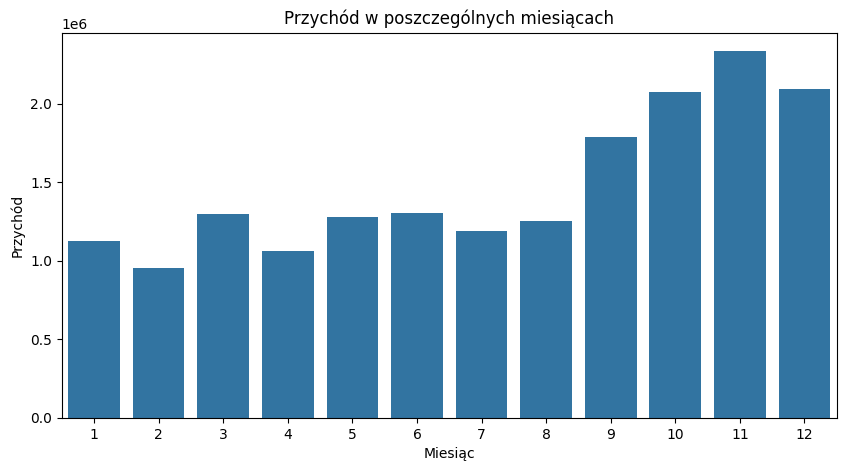

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.barplot(data=sprzedaż_miesięczna, x="Miesiąc", y="Przychód")

plt.title("Przychód w poszczególnych miesiącach")
plt.xlabel("Miesiąc")
plt.ylabel("Przychód")
plt.show()

### Ramka danych agregująca informacje o klientach

In [11]:
sprzedaż = transakcje.loc[transakcje['RodzajTransakcji'] == \
                          'standardowa_sprzedaż_klient'].copy()

print(sprzedaż.isna().sum())

df_klienci = sprzedaż.groupby("CustomerID").agg(
    Przychód=("WartośćTransakcji", "sum"),
    Liczba_Zamówień=("InvoiceNo", "nunique"),
    Sumaryczna_Ilość=("Quantity", "sum"),
    Liczba_Różnych_Produktów=("StockCode", "nunique"),
    Średnia_Cena_Jednostkowa=("UnitPrice", "mean"),
    Pierwszy_Zakup=("InvoiceDate", "min"),
    Ostatni_Zakup=("InvoiceDate", "max"))

data_koniec_okresu = sprzedaż["InvoiceDate"].max() + pd.Timedelta(days=1)
print(data_koniec_okresu)

df_klienci["Dni_Od_Ostatniego_Zakupu"] = (
    data_koniec_okresu - df_klienci["Ostatni_Zakup"]).dt.days

df_klienci["Dni_Aktywności_Klienta"] = (
    df_klienci["Ostatni_Zakup"] - df_klienci["Pierwszy_Zakup"]).dt.days + 1

df_klienci["Średnia_Wartość_Zamówienia"] = (
    df_klienci["Przychód"] / df_klienci["Liczba_Zamówień"])

print(df_klienci.head())

InvoiceNo            0
StockCode            0
Description          0
Quantity             0
InvoiceDate          0
UnitPrice            0
CustomerID           0
Country              0
RodzajTransakcji     0
WartośćTransakcji    0
dtype: int64


2011-12-10 12:50:00
            Przychód  Liczba_Zamówień  Sumaryczna_Ilość  \
CustomerID                                                
12346.0     77556.46               12             74285   
12347.0      5633.32                8              3286   
12348.0      2019.40                5              2714   
12349.0      4428.69                4              1624   
12350.0       334.40                1               197   

            Liczba_Różnych_Produktów  Średnia_Cena_Jednostkowa  \
CustomerID                                                       
12346.0                           27                  6.100000   
12347.0                          126                  2.546087   
12348.0                           25                  3.786275   
12349.0                          138                  8.459657   
12350.0                           17                  3.841176   

                Pierwszy_Zakup       Ostatni_Zakup  Dni_Od_Ostatniego_Zakupu  \
CustomerID             

### Ćwiczenie 3 – Macierz korelacji i mapa cieplna

In [12]:
m_korelacji = df_klienci.select_dtypes(include="number").corr(method="pearson")
m_korelacji.round(2)

,Przychód,Liczba_Zamówień,Sumaryczna_Ilość,Liczba_Różnych_Produktów,Średnia_Cena_Jednostkowa,Dni_Od_Ostatniego_Zakupu,Dni_Aktywności_Klienta,Średnia_Wartość_Zamówienia
Przychód,1.00,0.63,0.87,0.41,0.01,-0.13,0.21,0.27
Liczba_Zamówień,0.63,1.00,0.58,0.69,-0.01,-0.26,0.44,0.04
Sumaryczna_Ilość,0.87,0.58,1.00,0.39,-0.01,-0.11,0.20,0.26
Liczba_Różnych_Produktów,0.41,0.69,0.39,1.00,-0.02,-0.33,0.50,0.05
Średnia_Cena_Jednostkowa,0.01,-0.01,-0.01,-0.02,1.00,0.05,-0.03,0.14
Dni_Od_Ostatniego_Zakupu,-0.13,-0.26,-0.11,-0.33,0.05,1.00,-0.56,-0.03
Dni_Aktywności_Klienta,0.21,0.44,0.20,0.50,-0.03,-0.56,1.00,0.02
Średnia_Wartość_Zamówienia,0.27,0.04,0.26,0.05,0.14,-0.03,0.02,1.00


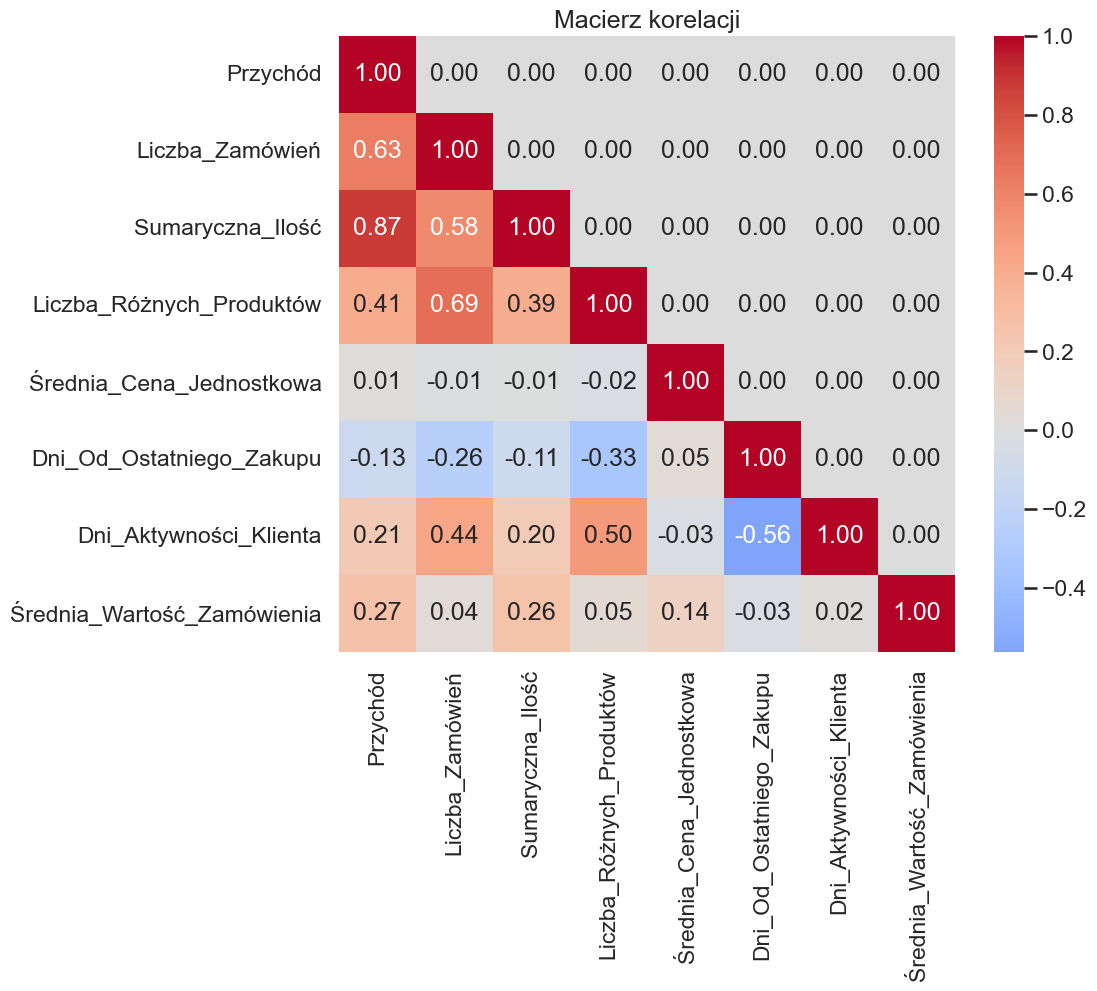

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(context='talk', style="whitegrid")

plt.figure(figsize=(10, 8))
sns.heatmap(
    np.tril(m_korelacji.to_numpy()),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    xticklabels=m_korelacji.columns,
    yticklabels=m_korelacji.columns)

plt.title("Macierz korelacji")
plt.show()

In [14]:
pary = m_korelacji.where(np.tril(np.ones(m_korelacji.shape, dtype=bool), k=-1)).stack()
print("Najsilniejsza korelacja dodatnia:", pary.idxmax(), round(pary.max(), 3))
print("Najsilniejsza korelacja ujemna:  ", pary.idxmin(), round(pary.min(), 3))

Najsilniejsza korelacja dodatnia: ('Sumaryczna_Ilość', 'Przychód') 0.874
Najsilniejsza korelacja ujemna:   ('Dni_Aktywności_Klienta', 'Dni_Od_Ostatniego_Zakupu') -0.564


**Odpowiedź (ćwiczenie 3):**
- **Najsilniejsza korelacja dodatnia:** `Przychód` – `Sumaryczna_Ilość` (r ≈ 0.87). Jest to wynik przewidywalny:
  im więcej sztuk klient kupuje, tym większy przychód generuje (przychód = suma ilość × cena).
  Wysokie wartości mają też pary `Liczba_Zamówień` – `Liczba_Różnych_Produktów` (≈ 0.69) oraz
  `Przychód` – `Liczba_Zamówień` (≈ 0.63).
- **Najsilniejsza korelacja ujemna:** `Dni_Od_Ostatniego_Zakupu` – `Dni_Aktywności_Klienta` (r ≈ −0.56).
  Klienci, którzy dawno nie kupowali, to zwykle klienci jednorazowi lub krótko aktywni; klienci aktywni przez
  długi okres zazwyczaj kupowali niedawno.
- `Średnia_Cena_Jednostkowa` praktycznie nie jest liniowo skorelowana z pozostałymi cechami (|r| ≈ 0).

### Autokorelacja dla opóźnienia 1 miesiąca

In [15]:
sprzedaż = transakcje.loc[transakcje['RodzajTransakcji'] == \
                          'standardowa_sprzedaż_klient'].copy()
przychód_miesięczny = (
    sprzedaż
    .set_index("InvoiceDate")
    .resample("MS")["WartośćTransakcji"].sum()
    .reset_index())

przychód_miesięczny["Przychód_Sprzed_1M"] = \
    przychód_miesięczny["WartośćTransakcji"].shift(1)

print(przychód_miesięczny.head(7))

pm = przychód_miesięczny.dropna(subset=
                                ["WartośćTransakcji", "Przychód_Sprzed_1M"])
auto_kor_1m = \
    przychód_miesięczny["WartośćTransakcji"].corr(pm["Przychód_Sprzed_1M"])

print("Autokorelacja (Opóźnienie 1 miesiąc):", auto_kor_1m)

  InvoiceDate  WartośćTransakcji  Przychód_Sprzed_1M
0  2009-12-01         686654.160                 NaN
1  2010-01-01         557319.062          686654.160
2  2010-02-01         506371.066          557319.062
3  2010-03-01         699608.991          506371.066
4  2010-04-01         594609.192          699608.991
5  2010-05-01         599985.790          594609.192
6  2010-06-01         639066.580          599985.790
Autokorelacja (Opóźnienie 1 miesiąc): 0.5268488951587175


### Ćwiczenie 4 – Autokorelacja dla opóźnienia 12 miesięcy

In [16]:
przychód_miesięczny["Przychód_Sprzed_12M"] = \
    przychód_miesięczny["WartośćTransakcji"].shift(12)

pm12 = przychód_miesięczny.dropna(subset=
                                  ["WartośćTransakcji", "Przychód_Sprzed_12M"])
print("Liczba par obserwacji:", len(pm12))
print(pm12[["InvoiceDate", "WartośćTransakcji", "Przychód_Sprzed_12M"]])

auto_kor_12m = pm12["WartośćTransakcji"].corr(pm12["Przychód_Sprzed_12M"])
print("Autokorelacja (Opóźnienie 12 miesięcy):", auto_kor_12m)

print("Series.autocorr(lag=12):", przychód_miesięczny["WartośćTransakcji"].autocorr(lag=12))

Liczba par obserwacji: 13
   InvoiceDate  WartośćTransakcji  Przychód_Sprzed_12M
12  2010-12-01         884591.890           686654.160
13  2011-01-01         569445.040           557319.062
14  2011-02-01         447137.350           506371.066
15  2011-03-01         595500.760           699608.991
16  2011-04-01         469200.361           594609.192
17  2011-05-01         678594.560           599985.790
18  2011-06-01         661213.690           639066.580
19  2011-07-01         600091.011           591636.740
20  2011-08-01         645343.900           604242.650
21  2011-09-01         952838.382           831615.001
22  2011-10-01        1039318.790          1036680.000
23  2011-11-01        1161817.380          1172336.042
24  2011-12-01         518210.790           884591.890
Autokorelacja (Opóźnienie 12 miesięcy): 0.8025167760175206
Series.autocorr(lag=12): 0.8025167760175206


**Interpretacja (ćwiczenie 4):** autokorelacja dla opóźnienia 12 miesięcy wynosi ok. **0.80**, czyli jest wyraźnie
wyższa niż dla opóźnienia 1 miesiąca (0.53). Oznacza to silną dodatnią zależność między przychodem w danym
miesiącu a przychodem w tym samym miesiącu rok wcześniej – potwierdza to **roczną sezonowość** sprzedaży
(wzrost jesienią, szczyt w październiku–listopadzie, spadek na początku roku).

Należy pamiętać, że wynik opiera się tylko na 13 parach obserwacji, więc jest obarczony dużą niepewnością.
Dodatkowo grudzień 2011 obejmuje dane tylko do 9 grudnia, przez co jego przychód jest zaniżony – co obniża
wartość współczynnika (bez tej obserwacji autokorelacja byłaby jeszcze wyższa, patrz komórka poniżej).

In [17]:
pm12_pełne = pm12[pm12["InvoiceDate"] < "2011-12-01"]
print("Autokorelacja 12M (bez XII 2011):",
      pm12_pełne["WartośćTransakcji"].corr(pm12_pełne["Przychód_Sprzed_12M"]))

Autokorelacja 12M (bez XII 2011): 0.9197068874720477
